Epoch 1/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.6099 - loss: 0.6503 - val_accuracy: 0.7096 - val_loss: 0.5652
Epoch 2/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 39s 64ms/step - accuracy: 0.6952 - loss: 0.5783 - val_accuracy: 0.7504 - val_loss: 0.5340
Epoch 3/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 41s 64ms/step - accuracy: 0.7258 - loss: 0.5393 - val_accuracy: 0.7521 - val_loss: 0.5076
Epoch 4/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 41s 64ms/step - accuracy: 0.7535 - loss: 0.5016 - val_accuracy: 0.7928 - val_loss: 0.4478
Epoch 5/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 36s 60ms/step - accuracy: 0.7715 - loss: 0.4756 - val_accuracy: 0.8098 - val_loss: 0.4225
Epoch 6/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 39s 63ms/step - accuracy: 0.7865 - loss: 0.4555 - val_accuracy: 0.8160 - val_loss: 0.4067
Epoch 7/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 41s 63ms/step - accuracy: 0.7996 - loss: 0.4338 - val_accuracy: 0.8265 - val_loss: 0.3880
Epoch 8/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 38s 63ms/step - accuracy: 0.8089 - loss: 0.4154 - 

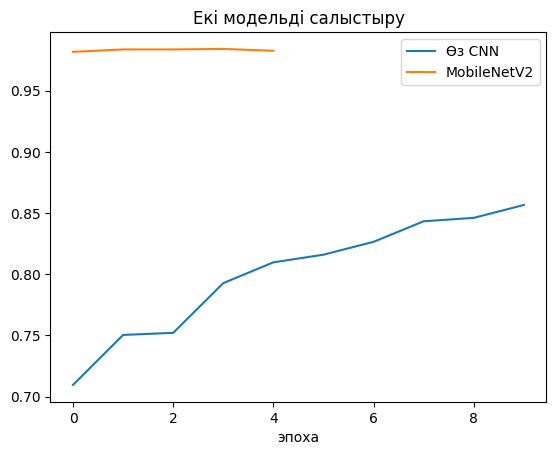

In [2]:
!pip install -q importlib_resources
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

(train_raw, val_raw), info = tfds.load(
    "cats_vs_dogs", split=["train[:80%]", "train[80%:]"],
    as_supervised=True, with_info=True)

def prep(img, label):
    return tf.image.resize(img, (160, 160)), label

train = train_raw.map(prep).shuffle(1000).batch(32).prefetch(tf.data.AUTOTUNE)
val = val_raw.map(prep).batch(32).prefetch(tf.data.AUTOTUNE)

aug = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)])

cnn = models.Sequential([
    layers.Input((160,160,3)),
    aug, layers.Rescaling(1./255),
    layers.Conv2D(32,3,activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128,3,activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dropout(0.5),
    layers.Dense(128,activation="relu"),
    layers.Dense(1,activation="sigmoid")])
cnn.compile("adam","binary_crossentropy",metrics=["accuracy"])
hist = cnn.fit(train, validation_data=val, epochs=10)

base = tf.keras.applications.MobileNetV2(
    input_shape=(160,160,3), include_top=False, weights="imagenet")
base.trainable = False

mob = models.Sequential([
    layers.Input((160,160,3)),
    aug,
    layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")])
mob.compile("adam","binary_crossentropy",metrics=["accuracy"])
hist2 = mob.fit(train, validation_data=val, epochs=5)

plt.plot(hist.history["val_accuracy"], label="Өз CNN")
plt.plot(hist2.history["val_accuracy"], label="MobileNetV2")
plt.legend(); plt.title("Екі модельді салыстыру"); plt.xlabel("эпоха"); plt.show()

146/146 ━━━━━━━━━━━━━━━━━━━━ 20s 113ms/step


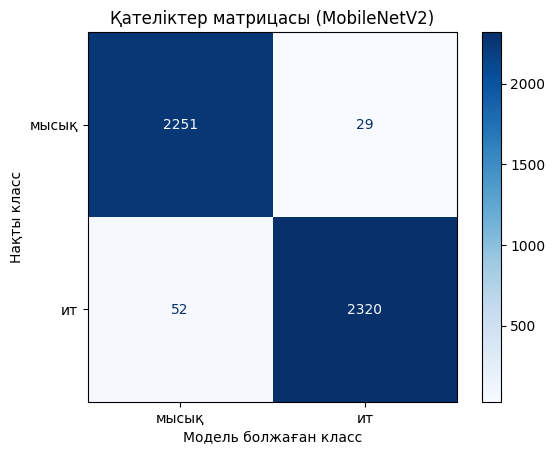

Мысықты дұрыс тапқаны: 2251 / 2280
Итті дұрыс тапқаны: 2320 / 2372
Жалпы дәлдік: 98.26 %


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = np.concatenate([y.numpy() for _, y in val])
y_pred = (mob.predict(val).ravel() > 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["мысық", "ит"])
disp.plot(cmap="Blues", values_format="d")

plt.title("Қателіктер матрицасы (MobileNetV2)")
plt.xlabel("Модель болжаған класс")
plt.ylabel("Нақты класс")
plt.savefig("confusion.png", dpi=200)
plt.show()

print("Мысықты дұрыс тапқаны:", cm[0,0], "/", cm[0].sum())
print("Итті дұрыс тапқаны:", cm[1,1], "/", cm[1].sum())
print("Жалпы дәлдік:", round((cm[0,0] + cm[1,1]) / cm.sum() * 100, 2), "%")

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


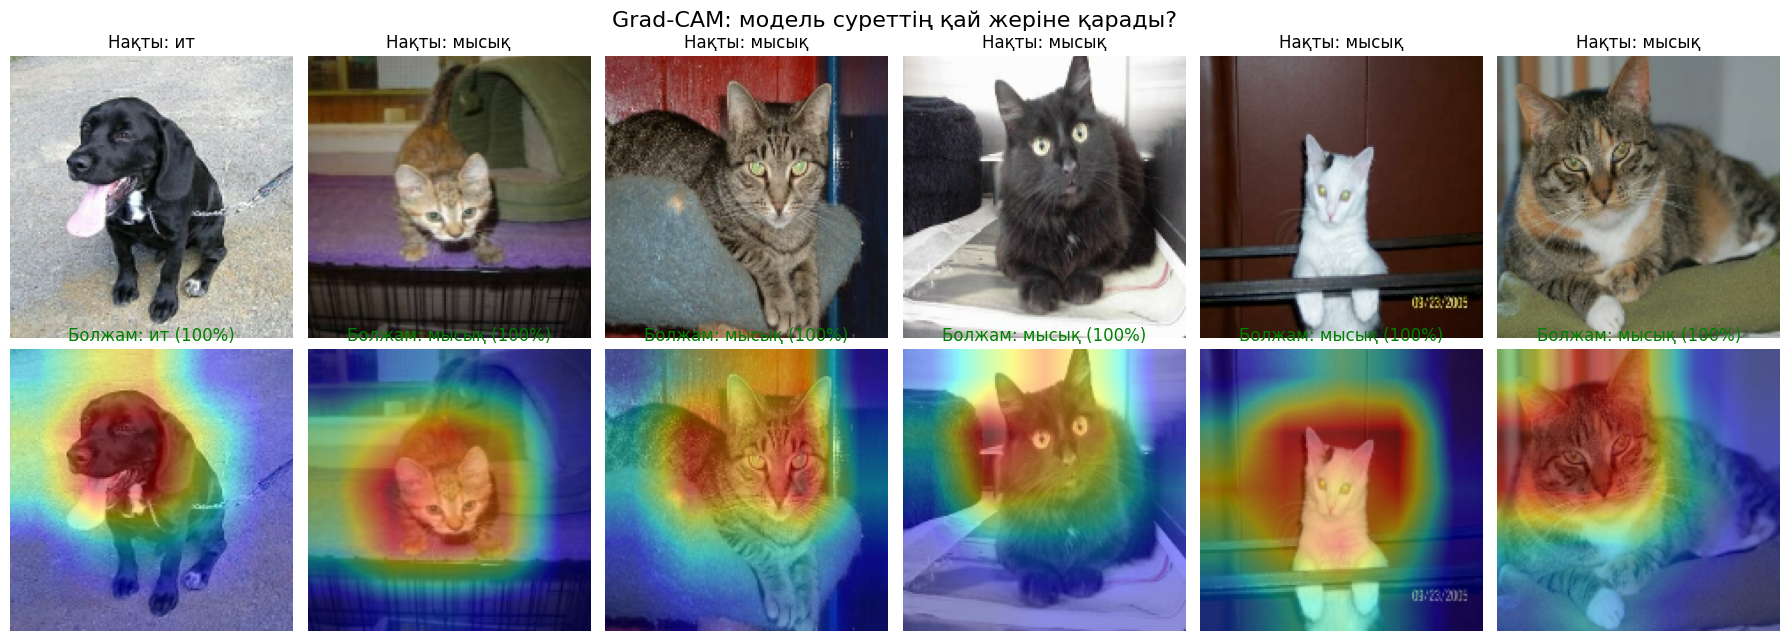

In [5]:
import numpy as np
import matplotlib.pyplot as plt

last_conv = base.get_layer("out_relu")
grad_base = tf.keras.Model(base.input, [last_conv.output, base.output])
gap = [l for l in mob.layers if isinstance(l, layers.GlobalAveragePooling2D)][0]
dense = mob.layers[-1]

def gradcam(img):
    """img: 160x160x3 массиві (0-255). Қайтарады: жылу картасы, итке жататын ықтималдық"""
    x = tf.convert_to_tensor(img[None], dtype=tf.float32)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    with tf.GradientTape() as tape:
        conv, feat = grad_base(x)
        pooled = gap(feat)
        logit = tf.matmul(pooled, dense.kernel) + dense.bias
        score = tf.where(logit[:, 0] > 0, logit[:, 0], -logit[:, 0])
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    heat = tf.reduce_sum(conv * weights[:, None, None, :], axis=-1)[0]
    heat = tf.nn.relu(heat)
    heat = heat / (tf.reduce_max(heat) + 1e-8)
    heat = tf.image.resize(heat[..., None], (160, 160))[..., 0].numpy()
    p_dog = float(tf.sigmoid(logit)[0, 0])
    return heat, p_dog

skip = np.random.randint(0, 100)
imgs, labels = next(iter(val.skip(skip).take(1)))
names = ["мысық", "ит"]

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for i in range(6):
    img = imgs[i].numpy()
    heat, p = gradcam(img)
    pred = 1 if p > 0.5 else 0
    conf = p if pred == 1 else 1 - p
    true = int(labels[i])
    color = "green" if pred == true else "red"

    axes[0, i].imshow(img.astype("uint8")); axes[0, i].axis("off")
    axes[0, i].set_title(f"Нақты: {names[true]}")

    axes[1, i].imshow(img.astype("uint8"))
    axes[1, i].imshow(heat, cmap="jet", alpha=0.45); axes[1, i].axis("off")
    axes[1, i].set_title(f"Болжам: {names[pred]} ({conf*100:.0f}%)", color=color)

plt.suptitle("Grad-CAM: модель суреттің қай жеріне қарады?", fontsize=16)
plt.tight_layout()
plt.savefig("gradcam.png", dpi=200)
plt.show()

In [6]:
!pip install -q ultralytics gradio

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from matplotlib import cm


DO_FINETUNE = False
DET_CONF_HIGH = 0.50
DET_CONF_LOW = 0.15
GATE_THRESHOLD = 0.25
FULL_GATE = 0.40

if DO_FINETUNE:
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    mob.compile(tf.keras.optimizers.Adam(1e-5), "binary_crossentropy", metrics=["accuracy"])
    hist3 = mob.fit(train, validation_data=val, epochs=4)
    mob.save("mobilenet_catdog.keras")


last_conv = base.get_layer("out_relu")
grad_base = tf.keras.Model(base.input, [last_conv.output, base.output])
gap = [l for l in mob.layers if isinstance(l, layers.GlobalAveragePooling2D)][0]
dense = mob.layers[-1]

def gradcam(img):
    x = tf.convert_to_tensor(img[None], dtype=tf.float32)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    with tf.GradientTape() as tape:
        conv, feat = grad_base(x)
        pooled = gap(feat)
        logit = tf.matmul(pooled, dense.kernel) + dense.bias
        score = tf.where(logit[:, 0] > 0, logit[:, 0], -logit[:, 0])
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    heat = tf.reduce_sum(conv * weights[:, None, None, :], axis=-1)[0]
    heat = tf.nn.relu(heat)
    heat = heat / (tf.reduce_max(heat) + 1e-8)
    return tf.image.resize(heat[..., None], (160, 160))[..., 0].numpy()


gate = tf.keras.applications.MobileNetV2(weights="imagenet")

def animal_score(img):
    """Суретте мысық немесе ит болу ықтималдығы"""
    x = tf.image.resize(tf.convert_to_tensor(img, tf.float32), (224, 224))[None]
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    probs = gate(x, training=False).numpy()[0]
    return float(probs[151:269].sum() + probs[281:286].sum())


from ultralytics import YOLO
detector = YOLO("yolov8s.pt")

def find_animals(img):
    h, w = img.shape[:2]
    res = detector.predict(np.ascontiguousarray(img[..., ::-1]), conf=DET_CONF_LOW,
                           classes=[15, 16], agnostic_nms=True, verbose=False)[0]
    found = []
    for (x1, y1, x2, y2), conf in zip(res.boxes.xyxy.cpu().numpy(),
                                      res.boxes.conf.cpu().numpy()):
        pw, ph = 0.08 * (x2 - x1), 0.08 * (y2 - y1)
        x1, y1 = int(max(0, x1 - pw)), int(max(0, y1 - ph))
        x2, y2 = int(min(w, x2 + pw)), int(min(h, y2 + ph))
        if x2 - x1 < 10 or y2 - y1 < 10:
            continue
        crop = img[y1:y2, x1:x2]
        if conf >= DET_CONF_HIGH or animal_score(crop) >= GATE_THRESHOLD:
            found.append((float(conf), (x1, y1, x2, y2)))
    found.sort(key=lambda t: -t[0])
    return found[:4]


def classify_crop(crop):
    """Қиылған жануар суреті бойынша итке жататын ықтималдықты қайтарады"""
    c = tf.image.resize(tf.convert_to_tensor(crop, tf.float32), (160, 160))
    flip = tf.reverse(c, axis=[1])
    variants = [c, flip,
                tf.image.adjust_contrast(c, 1.4),
                tf.image.adjust_contrast(flip, 1.4)]
    batch = tf.clip_by_value(tf.stack(variants), 0, 255)
    p = float(np.mean(mob(batch, training=False).numpy()))
    return p, c.numpy()


def predict(img):
    if img is None:
        return {"Сурет жүктеңіз": 1.0}, None, None
    img = np.array(img)
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)
    img = img[..., :3].astype("uint8")
    h, w = img.shape[:2]

    animals = find_animals(img)
    if not animals:
        if animal_score(img) >= FULL_GATE:
            animals = [(1.0, (0, 0, w, h))]
        else:
            return {"❌ Бұл мысық та, ит те емес": 1.0}, (img, []), None

    annotations, main = [], None
    for conf, (x1, y1, x2, y2) in animals:
        p, crop160 = classify_crop(img[y1:y2, x1:x2])
        name = "Ит 🐶" if p > 0.5 else "Мысық 🐱"
        sure = max(p, 1 - p)
        annotations.append(((x1, y1, x2, y2), f"{name} {sure*100:.0f}%"))
        if main is None:
            main = (p, crop160)

    p, crop160 = main
    heat = gradcam(crop160)
    colored = cm.jet(heat)[..., :3] * 255
    overlay = (0.6 * crop160 + 0.4 * colored).astype("uint8")
    return {"Мысық 🐱": 1 - p, "Ит 🐶": p}, (img, annotations), overlay


import gradio as gr

try:
    demo.close()
except Exception:
    pass

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(label="Сурет жүктеңіз"),
    outputs=[gr.Label(num_top_classes=2, label="Болжам"),
             gr.AnnotatedImage(label="Табылған жануар"),
             gr.Image(label="Модель қайда қарады (Grad-CAM)")],
    title="Мысық па, ит пе? 🐱🐶",
    description="Нейрондық желі суреттен мысық пен итті іздейді. Адам немесе басқа зат болса, оларға мән бермейді, тек жануарды тауып, қайсысы екенін анықтайды. Жануар жоқ болса, «мысық та, ит те емес» деп жауап береді.")
demo.launch(share=True)

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://691e00a9d303d1dba6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


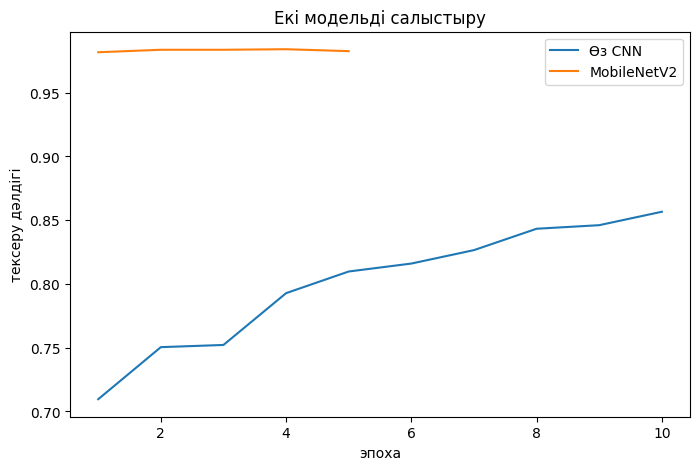

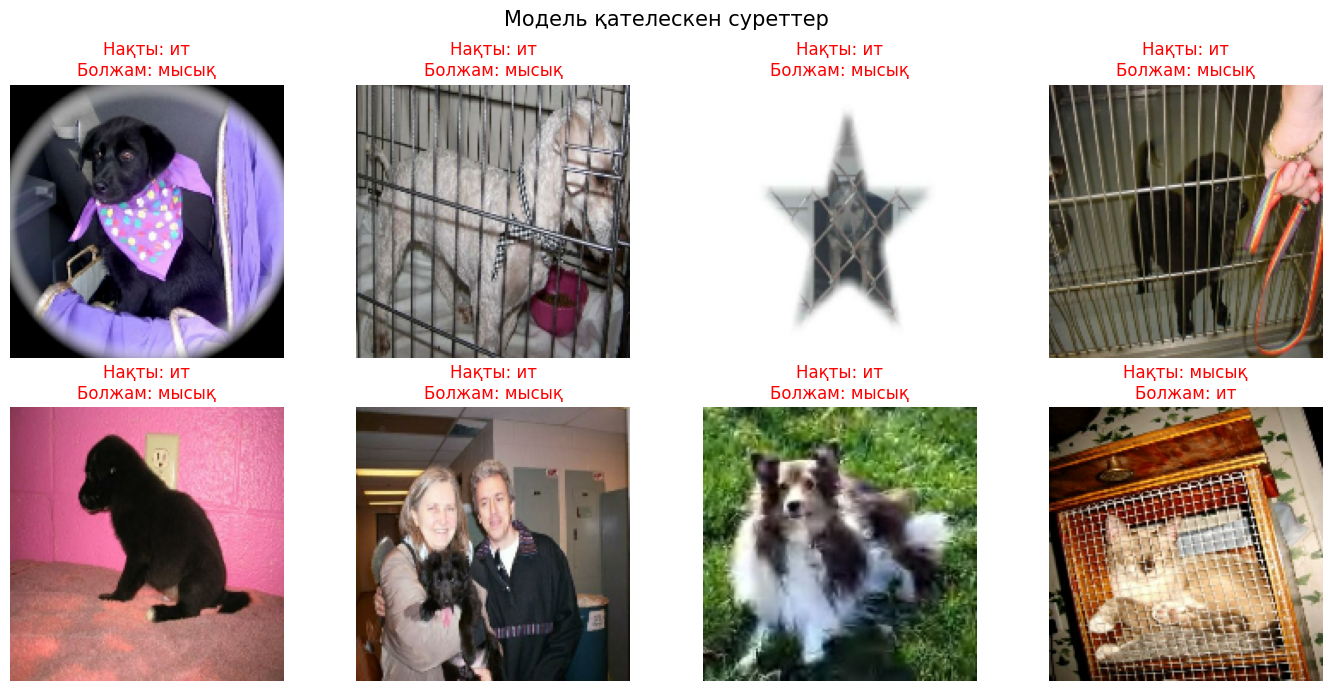

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# compare.png
mob_acc = hist2.history["val_accuracy"]
try:
    mob_acc = mob_acc + hist3.history["val_accuracy"]
except NameError:
    pass
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(hist.history["val_accuracy"]) + 1), hist.history["val_accuracy"], label="Өз CNN")
plt.plot(range(1, len(mob_acc) + 1), mob_acc, label="MobileNetV2")
plt.legend(); plt.title("Екі модельді салыстыру")
plt.xlabel("эпоха"); plt.ylabel("тексеру дәлдігі")
plt.savefig("compare.png", dpi=200); plt.show()

# errors.png
names = ["мысық", "ит"]
wrong_imgs, wrong_true, wrong_p = [], [], []
for x, y in val:
    p = mob.predict(x, verbose=0).ravel()
    for i in np.where((p > 0.5).astype(int) != y.numpy())[0]:
        wrong_imgs.append(x[i].numpy().astype("uint8"))
        wrong_true.append(int(y[i])); wrong_p.append(float(p[i]))
    if len(wrong_imgs) >= 8:
        break
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for a in ax.ravel():
    a.axis("off")
for a, im, t, p in zip(ax.ravel(), wrong_imgs, wrong_true, wrong_p):
    a.imshow(im)
    a.set_title(f"Нақты: {names[t]}\nБолжам: {names[1 if p > 0.5 else 0]}", color="red")
plt.suptitle("Модель қателескен суреттер", fontsize=15)
plt.tight_layout(); plt.savefig("errors.png", dpi=200); plt.show()

# модельді сақтау
mob.save("mobilenet_catdog.keras")